### CashyOS(Arch Linux 변형판)에서 돌림

In [13]:
import os
import re
import time
import uuid
import pickle
import argparse
import base64
import tempfile
from pathlib import Path

from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
from langchain_classic.storage import InMemoryStore
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

from IPython.display import Image, display
from unstructured.partition.pdf import partition_pdf

from langchain_text_splitters import CharacterTextSplitter
from collections import Counter
from langchain_core.documents import Document as _Doc

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요 (예: "invest.pdf")
fname = "CN7_2021_ko_KR_100-120.pdf"

fpath = str(PROJECT_ROOT / "data") + os.sep

processed = PROJECT_ROOT / "data" / "processed"
figures_prac_dir = PROJECT_ROOT / "data" / "figures_prac"

print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", fpath)
print("PDF 존재 여부:", os.path.exists(fpath + fname))

# .env 파일에서 API 키를 불러옵니다
load_dotenv(PROJECT_ROOT / ".env")
openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("OpenAI API 키가 없습니다. .env 파일을 확인하세요.")

print("API 키 로드 완료:", openai_api_key[:7] + "..." + openai_api_key[-4:])

print("  이미지 폴더 :", figures_prac_dir, "(존재:", figures_prac_dir.exists(), ")")

프로젝트 루트: /home/gyujin/Work/PythonProject/MultiModal
PDF 폴더     : /home/gyujin/Work/PythonProject/MultiModal/data/
PDF 존재 여부: True
API 키 로드 완료: sk-proj...lJkA
  이미지 폴더 : /home/gyujin/Work/PythonProject/MultiModal/data/figures_prac (존재: True )


In [ ]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",                  # TODO 2: 정밀 추출 전략
        extract_images_in_pdf=True,       # TODO 3: 이미지를 추출할까요?
        infer_table_structure=True,       # TODO 4: 표 구조를 추론할까요?
        chunking_strategy="by_title",     # 타이틀 기준으로 텍스트 분할
        max_characters=4000,              # 최대 4000자로 블록 제한
        new_after_n_chars=3800,           # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,  # 2000자 이하는 결합
        extract_image_block_output_dir=path+"/figures_prac"       # 이미지 저장 경로
    )


print("extract_pdf_elements 정의 완료")

def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # TODO 5: 표는 어느 리스트로?
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))     # TODO 6: 텍스트는 어느 리스트로?

    return texts, tables

print("categorize_elements 정의 완료")


def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 요약본을 생성합니다.

    texts          : 텍스트 리스트
    tables         : 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부
    """

    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
        이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
        주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
        요약할 표 또는 텍스트: {element}"""

    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    # TODO 1: 사용할 모델 이름을 적으세요
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    # TODO 2, 3: 컨베이어 벨트의 2번, 3번 칸을 채우세요
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []

    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

    return text_summaries, table_summaries


print("generate_text_summaries 정의 완료")


def encode_image(image_path):
    """이미지를 base64 문자열로 변환"""
    with open(image_path, "rb") as image_file:
        # TODO 5: 어떤 인코딩으로 디코딩할까요?
        return base64.b64encode(image_file.read()).decode("utf-8")

def image_summarize(img_base64, prompt):
    """이미지 요약 생성 (VLM 호출)"""
    # TODO 6: 비전 기능이 있는 모델 이름을 적으세요
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {
                "type": "image_url",
                # TODO 7: 접두사 뒤에 들어갈 변수 이름을 적으세요
                "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
            },
        ])
    ])
    return msg.content

def generate_img_summaries(path):
    """이미지의 요약과 Base64 인코딩 문자열을 생성"""
    img_base64_list = []
    image_summaries = []

    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
        These summaries will be embedded and used to retrieve the raw image.
        Provide a concise summary of the image that is well optimized for retrieval.
        The summary should be written in Korean (Hangul)."""

    for img_file in sorted(os.listdir(path)):
        # TODO 8: 처리할 확장자를 튜플로 적으세요
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

    return img_base64_list, image_summaries



def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        _Doc(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    # TODO 1: 요약본은 어디에 넣을까요? (vectorstore / docstore)
    retriever.vectorstore.add_documents(summary_docs)

    # TODO 2: 원본은 어디에 넣을까요?
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))


def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
    b64_images = []
    texts_out = []

    for doc in docs:
        doc = doc.page_content if isinstance(doc, Document) else doc
        # Base64 문자열은 영문/숫자/+/= 만으로 길게 이어집니다
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", doc):
            b64_images.append(doc)
        else:
            texts_out.append(doc)

    return {"images": b64_images, "texts": texts_out}

def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    # 1) 이미지를 먼저 넣습니다 (모델이 그림을 먼저 보게)
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            # TODO 4: Base64 앞에 붙일 접두사를 완성하세요
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    # 2) 텍스트 컨텍스트와 질문을 넣습니다
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": (
            "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
            "자료에 없는 내용은 모른다고 답하세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n{formatted_texts}"
        ),
    })

    return [HumanMessage(content=messages)]


extract_pdf_elements 정의 완료
categorize_elements 정의 완료
generate_text_summaries 정의 완료


Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 1643.73it/s]


추출 완료 — 170.3초 소요
추출된 전체 요소 수: 51
텍스트 블록 수: 27
표 블록 수    : 24
CompositeElement      : 27개
Table                 : 24개
추출된 이미지: 21개

  figure-15-8.jpg  (29 KB)
  figure-16-10.jpg  (27 KB)
  figure-16-9.jpg  (3 KB)
  figure-17-11.jpg  (25 KB)
  figure-17-12.jpg  (28 KB)
  figure-17-13.jpg  (29 KB)
  figure-18-14.jpg  (25 KB)
  figure-18-15.jpg  (25 KB)
  figure-18-16.jpg  (3 KB)
  figure-19-17.jpg  (27 KB)


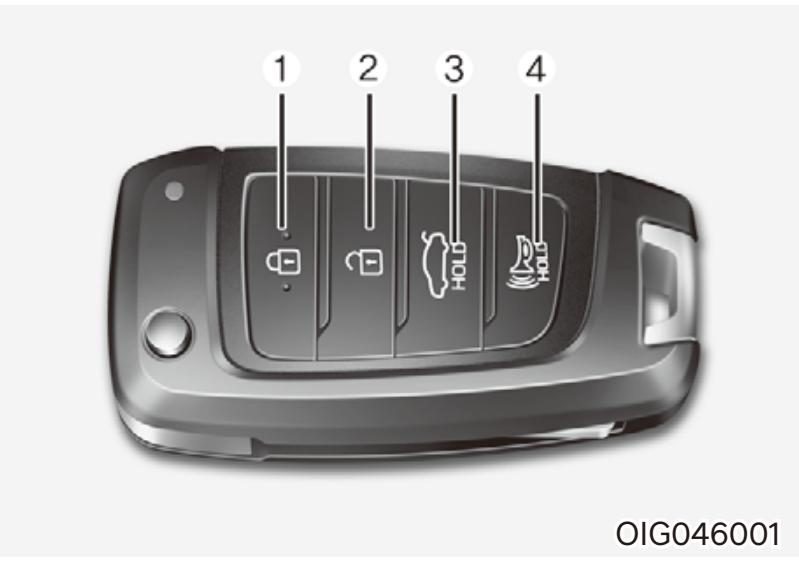

In [4]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))


type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")



if figures_prac_dir.exists():
    image_files = sorted(
        f for f in figures_prac_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")


# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_prac_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")



In [9]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

print("주피터1 ")

원본 블록 수  : 27
분할 후 블록 수: 13
전체 글자 수  : 11954
저장 완료: /home/gyujin/Work/PythonProject/MultiModal/data/processed/extracted.pkl
주피터1 


불러오기 완료: /home/gyujin/Work/PythonProject/MultiModal/data/processed/extracted.pkl
  텍스트 블록 : 27
  표 블록     : 24
  분할 텍스트 : 13
요약 완료 — 20.4초 소요
텍스트 요약 수: 13
표 요약 수    : 24
[원본] texts_2k_token[0] — 앞 300자
계기판

디지털 키 운전자 보조

• 고속도로 주행 보조: 고속도로에서 운전자가 설정한 속도와 전방 차량과의 안전거리 및 4-28

04 도어 4-29

계기판

라이트 사운드 웰컴 사운드 기능을 설정 또는 해제할 수 있습니다.

편의 4-30

서비스 시기 알림 테마 선택

계기판 그래픽 스타일과 설정을 선택할 수 있습니다.

• 테마 A / 테마 B / 테마 C

부가 기능 • psi / kPa / bar

언어/Language

olof

언어

계기판에 표시되는 언어를 선택할 수 있습니다.

(한글/영어)

설정 초기화

사

[요약] text_summaries[0]
**계기판 요약**

- **디지털 키 및 운전자 보조 기능**: 고속도로 주행 보조 기능 제공.
- **설정 기능**: 라이트, 사운드, 서비스 시기 알림, 계기판 그래픽 스타일(테마 A/B/C) 설정 가능.
- **언어 선택**: 한글 및 영어 지원.
- **초기화 옵션**: 사용자 설정 메뉴 초기화 가능, 언어 및 서비스 시기 알림 제외.
- **LCD 표시창**: 차량 사양에 따라 표시 내용이 다를 수 있음.
- **유틸리티 그룹**: 연비 정보, 주행 정보 등 표시. 주행 정보는 주행 거리, 연비, 주행 시간 포함. 정보 초기화는 'OK' 버튼 길게 누르거나 4시간 후 자동 초기화.

압축률: 1000자 → 334자 (33.4%)
표 요약 24건 생성됨

[표 요약 예시]
디지털 키 사용 설정 및 해제 가능. 스마트폰 및 카드키 등록/삭제 가능. 자세한 내용은 5장 「디지털 키」 참조.
원본 파일 : figure-15-8.jp

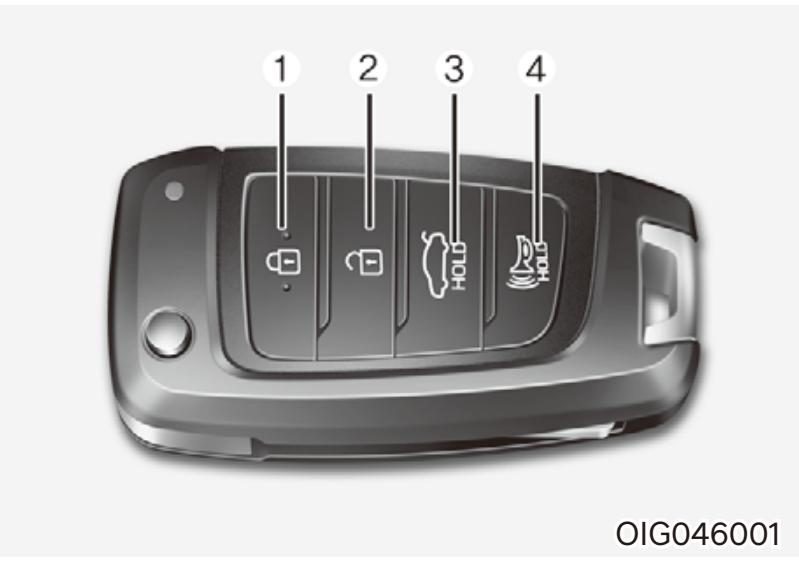

요약: 차 키의 상단 부분을 보여주는 이미지. 네 개의 버튼(잠금, 잠금 해제, 트렁크 열기, 경적)과 버튼 번호가 표시됨.

[1] figure-16-10.jpg


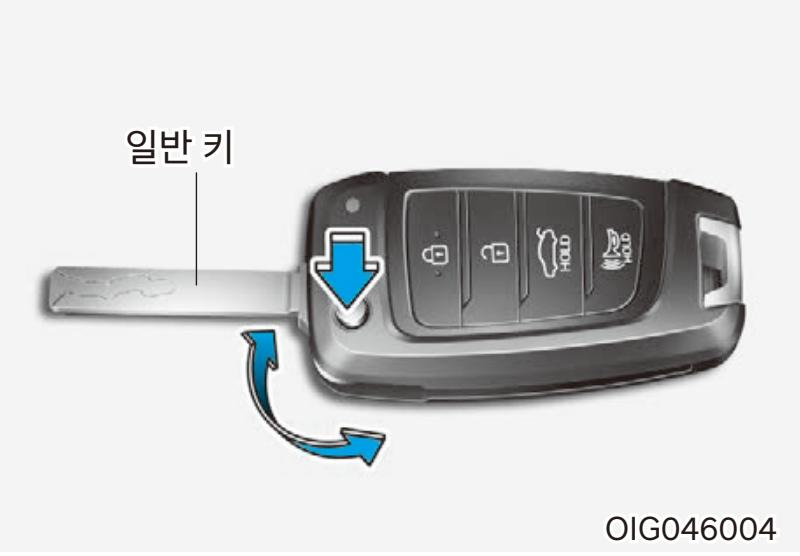

요약: 자동차 키의 디자인을 보여주는 이미지. 키는 일반 키와 버튼으로 구성되어 있으며, 버튼을 눌러서 일반 키를 펼치는 방식이다.

[2] figure-16-9.jpg


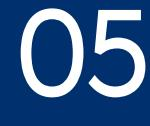

요약: 파란 배경에 큰 숫자 "05"가 하얀색으로 표시된 이미지.

텍스트 요약 토큰 사용량 (추정)
  입력 : 7,228 토큰
  출력 : 3,396 토큰
  합계 : 10,624 토큰

요약한 이미지 수: 21 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.
저장 완료: /home/gyujin/Work/PythonProject/MultiModal/data/processed/summaries.pkl
주피터2


In [10]:
pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

with open(pkl_path, "rb") as f:
    data = pickle.load(f)

texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

print("불러오기 완료:", pkl_path)
print("  텍스트 블록 :", len(texts))
print("  표 블록     :", len(tables))
print("  분할 텍스트 :", len(texts_2k_token))

start = time.time()

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수    :", len(table_summaries))

print("=" * 70)
print("[원본] texts_2k_token[0] — 앞 300자")
print("=" * 70)
print(texts_2k_token[0][:300])
print()

print("=" * 70)
print("[요약] text_summaries[0]")
print("=" * 70)
print(text_summaries[0])
print()

orig = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률: {orig}자 → {summ}자 ({summ / orig * 100:.1f}%)")

if table_summaries:
    print(f"표 요약 {len(table_summaries)}건 생성됨\n")
    print("[표 요약 예시]")
    print(table_summaries[0])
else:
    print("표 요약이 비어 있습니다. 아래를 확인하세요.\n")
    print("  1) 4교시에서 strategy='hi_res' 를 넣었는가?")
    print("  2) PDF를 열어 표가 '진짜 표'인지, '그림으로 그린 표'인지 확인했는가?")
    print("     → 그림으로 된 표는 이미지로 추출되며, 6교시 이미지 요약이 처리합니다.")
    print("\n  둘 다 해당하지 않으면 정상입니다. 그대로 진행하세요.")

image_files = sorted(
    f for f in figures_prac_dir.iterdir()
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)

sample_b64 = encode_image(image_files[0])

print("원본 파일 :", image_files[0].name)
print("문자열 길이:", len(sample_b64), "자")
print("앞 100자  :", sample_b64[:100])

test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

print(image_summarize(sample_b64, test_prompt))



start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_prac_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))


for i, (img_file, summary) in enumerate(zip(image_files[:3], image_summaries[:3])):
    print("=" * 70)
    print(f"[{i}] {img_file.name}")
    print("=" * 70)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()


import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "summaries.pkl")

print("주피터2")

In [18]:
# 4교시 결과
with open(processed / "extracted.pkl", "rb") as f:
    d1 = pickle.load(f)
texts, tables, texts_2k_token = d1["texts"], d1["tables"], d1["texts_2k_token"]

# 5~6교시 결과
with open(processed / "summaries.pkl", "rb") as f:
    d2 = pickle.load(f)
text_summaries = d2["text_summaries"]
table_summaries = d2["table_summaries"]
image_summaries = d2["image_summaries"]
img_base64_list = d2["img_base64_list"]

print("복원 완료")
print(f"  텍스트  원본 {len(texts_2k_token):3d}건 / 요약 {len(text_summaries):3d}건")
print(f"  표      원본 {len(tables):3d}건 / 요약 {len(table_summaries):3d}건")
print(f"  이미지  원본 {len(img_base64_list):3d}건 / 요약 {len(image_summaries):3d}건")


vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)

store = InMemoryStore()
id_key = "doc_id"

retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    docstore=store,
    id_key=id_key,
)

print("검색기 생성 완료")



if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료")
print("  벡터 DB에 저장된 요약 수:", vectorstore._collection.count())

# TODO 3: 그래프나 표를 봐야만 답할 수 있는 질문을 적으세요
query = "스마트키의 A 타입은?"

found = retriever.invoke(query)

print("검색된 원본 수:", len(found))
print()

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()



# 앞서 검색한 결과로 동작 확인
split = split_image_text_types(found)
print("이미지:", len(split["images"]), "건")
print("텍스트:", len(split["texts"]), "건")




model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model                     # TODO 5: 답변을 생성할 모델
    | StrOutputParser()
)

print("최종 체인 조립 완료")

start = time.time()
answer = chain.invoke(query)

print(f"답변 생성 — {time.time() - start:.1f}초\n")
print("Q:", query)
print("-" * 70)
print(answer)

# 텍스트만 들어간 벡터 DB (= 11주차에 만든 것과 같은 구조)
text_only_store = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_only_store.add_texts(texts_2k_token)
text_only_retriever = text_only_store.as_retriever(search_kwargs={"k": 4})

text_only_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
    "자료에 없는 내용은 모른다고 답하세요.\n\n"
    "질문: {question}\n\n참고 텍스트:\n{context}"
)

text_only_chain = (
    {
        "context": text_only_retriever | (lambda docs: "\n".join(d.page_content for d in docs)),
        "question": RunnablePassthrough(),
    }
    | text_only_prompt
    | model
    | StrOutputParser()
)

print("비교용 텍스트 전용 RAG 준비 완료")


print("=" * 70)
print("질문:", query)
print("=" * 70)
print()

print("[BEFORE] 텍스트 전용 RAG")
print("-" * 70)
before = text_only_chain.invoke(query)
print(before)
print()

print("[AFTER] 멀티모달 RAG")
print("-" * 70)
after = chain.invoke(query)
print(after)
print()

print("=" * 70)
print("이 출력 전체를 캡처해 README.md에 넣으세요.")
print("=" * 70)

# 과제 제출물 6번 "질의응답 5건"을 그대로 만들어 주는 셀입니다.
questions = [
    query,
    "이 문서의 핵심 주제를 한 문장으로 요약해줘",
    "문서에 나온 표의 내용을 설명해줘",
    "가장 중요한 수치 3가지를 알려줘",
    "이 문서가 다루지 않는 내용은 무엇인지 알려줘",
]

rows = []
for q in questions:
    found_q = retriever.invoke(q)
    kinds = split_image_text_types(found_q)
    answer = chain.invoke(q)
    rows.append({
        "질문": q,
        "근거": f"이미지 {len(kinds['images'])}건 / 텍스트 {len(kinds['texts'])}건",
        "답변": answer,
    })
    print("=" * 70)
    print("Q:", q)
    print("근거:", rows[-1]["근거"])
    print("A:", answer[:400])
    print()

# README에 붙일 마크다운 표로 출력
print("\n" + "=" * 70)
print("아래를 복사해 README.md에 붙여넣으세요")
print("=" * 70 + "\n")
print("| 질문 | 근거가 된 원본 | 답변 |")
print("| --- | --- | --- |")
for r in rows:
    short = r["답변"].replace("\n", " ")[:120]
    print(f"| {r['질문']} | {r['근거']} | {short}... |")


print("주피터 3")

복원 완료
  텍스트  원본  13건 / 요약  13건
  표      원본  24건 / 요약  24건
  이미지  원본  21건 / 요약  21건
검색기 생성 완료
색인 완료
  벡터 DB에 저장된 요약 수: 290
검색된 원본 수: 1

[0] 텍스트/표 — 길이 439자
    • 스마트 키 방전 및 문제가 있을 때 또는 차량이 방전 됐을 때 차량을 잠그기 위해서는 실내에서 도어 잠 금 버튼을 이용하여 모든 도어를 잠그십시오.  • 스마트 키는 한 차에 카드형 스마트키를 포함하여 3 개만  ...

이미지: 0 건
텍스트: 1 건
최종 체인 조립 완료
답변 생성 — 1.2초

Q: 스마트키의 A 타입은?
----------------------------------------------------------------------
자료에 따르면 스마트키의 A 타입은 OCN7050005입니다.
비교용 텍스트 전용 RAG 준비 완료
질문: 스마트키의 A 타입은?

[BEFORE] 텍스트 전용 RAG
----------------------------------------------------------------------
스마트키의 A 타입은 OCN7050005입니다.

[AFTER] 멀티모달 RAG
----------------------------------------------------------------------
자료에 따르면 스마트키의 A 타입은 OCN7050005입니다.

이 출력 전체를 캡처해 README.md에 넣으세요.
Q: 스마트키의 A 타입은?
근거: 이미지 0건 / 텍스트 1건
A: 자료에 따르면 스마트키의 A 타입은 OCN7050005입니다.

Q: 이 문서의 핵심 주제를 한 문장으로 요약해줘
근거: 이미지 0건 / 텍스트 0건
A: 이 문서의 핵심 주제는 차량의 다양한 키 및 잠금 시스템 사용 방법과 주의사항에 대한 안내입니다.

Q: 문서에 나온 표의 내용을 설명해줘
근거: 이미지 0건 / 텍스트 1건
A: 문서에 나온 표의 